<a href="https://colab.research.google.com/github/PreethiR091/Deep-Learning/blob/main/Preethi_R_24BAD091_DL_Self_Learning_Assignment.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

DL Self Learning Assignment

Preethi R 24BAD091

In [1]:
!pip install -q gensim scikit-learn tensorflow transformers torch pandas matplotlib

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 27.8/27.8 MB 41.8 MB/s eta 0:00:00


Task 1 — Literature Exploration

Aim: To study and compare traditional, predictive and contextual word representation techniques.

This code implements One-Hot Encoding, Bag of Words, TF-IDF, N-grams and LSA using SVD. It also generates a comparison table covering more than six techniques.

In [4]:
import numpy as np
import pandas as pd
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.decomposition import TruncatedSVD

sentences = [
    "king queen prince princess royal palace",
    "king rules kingdom royal crown",
    "queen rules kingdom palace crown",
    "man woman boy girl family people",
    "cat dog animal pet puppy kitten",
    "dog puppy animal pet friendly",
    "cat kitten animal pet playful",
    "apple orange mango fruit sweet",
    "banana apple fruit healthy food",
    "orange mango fruit juice sweet",
    "car bus train vehicle road travel",
    "train railway station travel passenger",
    "doctor nurse hospital patient health",
    "student teacher school learning education",
    "python java programming computer code",
    "computer code software programming python",
    "data science machine learning artificial intelligence",
    "machine learning neural network deep learning",
    "artificial intelligence data science model",
    "bank money loan finance account",
    "river bank water flowing"
]

# One-Hot Encoding
onehot = CountVectorizer(binary=True)
onehot_matrix = onehot.fit_transform(sentences)
print("ONE-HOT / BINARY DOCUMENT REPRESENTATION:")
print(onehot_matrix.toarray()[:3])

# Bag of Words
bow = CountVectorizer()
bow_matrix = bow.fit_transform(sentences)
print("\nBAG OF WORDS:")
print(bow_matrix.toarray()[:3])

# TF-IDF
tfidf = TfidfVectorizer()
tfidf_matrix = tfidf.fit_transform(sentences)
print("\nTF-IDF:")
print(np.round(tfidf_matrix.toarray()[:3], 2))

# N-grams
ngram = CountVectorizer(ngram_range=(1, 2))
ngram_matrix = ngram.fit_transform(sentences)
print("\nSAMPLE N-GRAMS:")
print(ngram.get_feature_names_out()[:25])

# LSA using SVD
svd = TruncatedSVD(n_components=2, random_state=42)
lsa = svd.fit_transform(tfidf_matrix)
print("\nLSA REPRESENTATION:")
print(np.round(lsa[:5], 3))

# Comparison table
comparison = pd.DataFrame({
    "Technique": [
        "One-Hot", "BoW", "TF-IDF", "LSA",
        "Word2Vec", "GloVe", "FastText",
        "Keras Embedding", "BERT", "SBERT"
    ],
    "Representation": [
        "Binary", "Counts", "Weighted", "Dense",
        "Static", "Static", "Subword",
        "Trainable", "Contextual", "Sentence"
    ],
    "OOV Handling": [
        "No", "No", "No", "Limited",
        "No", "No", "Yes",
        "Requires OOV strategy", "Subwords", "Subwords"
    ],
    "Contextual": [
        "No", "No", "No", "No", "No",
        "No", "No", "Architecture-dependent",
        "Yes", "Yes"
    ],
    "Computational Cost": [
        "Low", "Low", "Low", "Moderate",
        "Moderate", "Moderate", "Moderate",
        "Variable", "High", "High"
    ]
})

print("\nCOMPARISON TABLE:")
display(comparison)

ONE-HOT / BINARY DOCUMENT REPRESENTATION:
[[0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 1 0 0 0 0
  0 0 0 0 0 0 0 0 0 1 0 0 0 0 0 1 1 0 0 0 1 0 0 0 1 0 0 0 0 0 0 0 0 0 0 0
  0 0]
 [0 0 0 0 0 0 0 0 0 0 0 0 1 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 1 1 0 0 0
  0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 1 1 0 0 0 0 0 0 0 0 0 0
  0 0]
 [0 0 0 0 0 0 0 0 0 0 0 0 1 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 1 0 0 0
  0 0 0 0 0 0 0 0 0 1 0 0 0 0 0 0 0 0 0 0 1 0 0 0 0 1 0 0 0 0 0 0 0 0 0 0
  0 0]]

BAG OF WORDS:
[[0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 1 0 0 0 0
  0 0 0 0 0 0 0 0 0 1 0 0 0 0 0 1 1 0 0 0 1 0 0 0 1 0 0 0 0 0 0 0 0 0 0 0
  0 0]
 [0 0 0 0 0 0 0 0 0 0 0 0 1 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 1 1 0 0 0
  0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 1 1 0 0 0 0 0 0 0 0 0 0
  0 0]
 [0 0 0 0 0 0 0 0 0 0 0 0 1 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 1 0 0 0
  0 0 0 0 0 0 0 0 0 1 0 0 0 0 0 0 0 0 0 0 1 0 0 0 0 1 0 0 0 0 0 0 0 0 0 0
  0 0]]

TF-IDF:
[[

,Technique,Representation,OOV Handling,Contextual,Computational Cost
0,One-Hot,Binary,No,No,Low
1,BoW,Counts,No,No,Low
2,TF-IDF,Weighted,No,No,Low
3,LSA,Dense,Limited,No,Moderate
4,Word2Vec,Static,No,No,Moderate
5,GloVe,Static,No,No,Moderate
6,FastText,Subword,Yes,No,Moderate
7,Keras Embedding,Trainable,Requires OOV strategy,Architecture-dependent,Variable
8,BERT,Contextual,Subwords,Yes,High
9,SBERT,Sentence,Subwords,Yes,High


Task 2 — Word Embedding Implementation

Aim: To implement Word2Vec using CBOW and Skip-gram, train FastText, and identify the five most similar words using cosine similarity.

This cell also tests FastText with an out-of-vocabulary word.

In [5]:
!pip -q install --upgrade gensim smart_open

from gensim.models import Word2Vec, FastText

sentences_task2 = [
    "king queen prince princess royal palace",
    "king rules kingdom royal crown",
    "queen rules kingdom palace crown",
    "man woman boy girl family people",
    "cat dog animal pet puppy kitten",
    "dog puppy animal pet friendly",
    "cat kitten animal pet playful",
    "apple orange mango fruit sweet",
    "banana apple fruit healthy food",
    "orange mango fruit juice sweet",
    "car bus train vehicle road travel",
    "train railway station travel passenger",
    "doctor nurse hospital patient health",
    "student teacher school learning education",
    "python java programming computer code",
    "computer code software programming python",
    "data science machine learning artificial intelligence",
    "machine learning neural network deep learning",
    "artificial intelligence data science model",
    "bank money loan finance account",
    "river bank water flowing"
]

tokens = [sentence.split() for sentence in sentences_task2]

# CBOW
cbow = Word2Vec(
    tokens, vector_size=50, window=3,
    min_count=1, sg=0, epochs=300,
    workers=1, seed=42
)

# Skip-gram
skipgram = Word2Vec(
    tokens, vector_size=50, window=3,
    min_count=1, sg=1, epochs=300,
    workers=1, seed=42
)

# FastText
fasttext = FastText(
    tokens, vector_size=50, window=3,
    min_count=1, sg=1, epochs=300,
    workers=1, seed=42
)

print("Vocabulary size:", len(skipgram.wv))

queries = ["king", "cat", "fruit", "python", "learning"]

for query in queries:
    print("\nQUERY:", query)

    for name, model in [
        ("CBOW", cbow),
        ("Skip-gram", skipgram),
        ("FastText", fasttext)
    ]:
        print("\n", name)
        for word, score in model.wv.most_similar(query, topn=5):
            print(word, round(float(score), 3))

# OOV Test
unknown = "kingdoms"

print("\nOOV TEST:")
print("Word2Vec vocabulary contains 'kingdoms':",
      unknown in skipgram.wv.key_to_index)

print("FastText vocabulary contains 'kingdoms':",
      unknown in fasttext.wv.key_to_index)

print("FastText OOV vector:")
print(fasttext.wv[unknown][:10])

Vocabulary size: 74

QUERY: king

 CBOW
queen 0.924
royal 0.908
train 0.906
prince 0.903
finance 0.902

 Skip-gram
queen 0.985
royal 0.984
train 0.982
prince 0.982
vehicle 0.98

 FastText
kingdom 0.999
prince 0.999
science 0.999
princess 0.999
learning 0.999

QUERY: cat

 CBOW
patient 0.908
bank 0.905
health 0.903
learning 0.896
woman 0.888

 Skip-gram
bank 0.982
patient 0.981
health 0.98
learning 0.98
car 0.978

 FastText
animal 0.996
royal 0.996
artificial 0.995
friendly 0.995
king 0.995

QUERY: fruit

 CBOW
programming 0.943
travel 0.943
train 0.938
hospital 0.938
nurse 0.936

 Skip-gram
train 0.987
programming 0.987
orange 0.987
apple 0.986
travel 0.986

 FastText
intelligence 0.998
banana 0.998
people 0.998
science 0.998
machine 0.998

QUERY: python

 CBOW
royal 0.933
travel 0.928
palace 0.914
family 0.91
woman 0.909

 Skip-gram
royal 0.986
travel 0.985
train 0.982
family 0.982
palace 0.981

 FastText
passenger 0.998
programming 0.998
science 0.998
palace 0.998
king 0.998

QUERY: 

Task 3 — Neural and Contextual Embeddings

Aim: To generate trainable neural embeddings using TensorFlow/Keras and explore contextual embeddings using pretrained BERT.

This single cell implements both approaches and compares the BERT representation of “bank” in two different contexts.

In [6]:
!pip -q install transformers torch

import numpy as np
import tensorflow as tf
import torch
from transformers import AutoTokenizer, AutoModel
from sklearn.metrics.pairwise import cosine_similarity

sentences = [
    "king queen prince princess royal palace",
    "king rules kingdom royal crown",
    "queen rules kingdom palace crown",
    "man woman boy girl family people",
    "cat dog animal pet puppy kitten",
    "dog puppy animal pet friendly",
    "cat kitten animal pet playful",
    "apple orange mango fruit sweet",
    "banana apple fruit healthy food",
    "orange mango fruit juice sweet",
    "car bus train vehicle road travel",
    "train railway station travel passenger",
    "doctor nurse hospital patient health",
    "student teacher school learning education",
    "python java programming computer code",
    "computer code software programming python",
    "data science machine learning artificial intelligence",
    "machine learning neural network deep learning",
    "artificial intelligence data science model",
    "bank money loan finance account",
    "river bank water flowing"
]

# Keras Embedding
tokenizer = tf.keras.preprocessing.text.Tokenizer()
tokenizer.fit_on_texts(sentences)

sequences = tokenizer.texts_to_sequences(sentences)
vocab_size = len(tokenizer.word_index) + 1

X, y = [], []

for seq in sequences:
    for i in range(1, len(seq)):
        X.append(seq[:i])
        y.append(seq[i])

X = tf.keras.preprocessing.sequence.pad_sequences(
    X, maxlen=6, padding="pre"
)
y = np.array(y)

model = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(6,)),
    tf.keras.layers.Embedding(vocab_size, 32, name="embedding"),
    tf.keras.layers.GlobalAveragePooling1D(),
    tf.keras.layers.Dense(32, activation="relu"),
    tf.keras.layers.Dense(vocab_size, activation="softmax")
])

model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

history = model.fit(X, y, epochs=50, verbose=0)

weights = model.get_layer("embedding").get_weights()[0]
word_id = tokenizer.word_index["king"]

print("KERAS EMBEDDING:")
print("Vocabulary size:", vocab_size)
print("Embedding dimension:", weights.shape[1])
print("King vector:", weights[word_id][:10])
print("Training accuracy:", history.history["accuracy"][-1])

# BERT
bert_name = "google-bert/bert-base-uncased"
bert_tokenizer = AutoTokenizer.from_pretrained(bert_name)
bert_model = AutoModel.from_pretrained(bert_name)
bert_model.eval()

def get_bert_vector(sentence, word):
    inputs = bert_tokenizer(sentence, return_tensors="pt")

    with torch.no_grad():
        output = bert_model(**inputs)

    tokens = bert_tokenizer.convert_ids_to_tokens(
        inputs["input_ids"][0]
    )

    positions = [i for i, token in enumerate(tokens) if token == word]

    return output.last_hidden_state[
        0, positions, :
    ].mean(dim=0).numpy()

sentence1 = "The bank approved the loan"
sentence2 = "The fisherman sat on the river bank"

vector1 = get_bert_vector(sentence1, "bank")
vector2 = get_bert_vector(sentence2, "bank")

similarity = cosine_similarity([vector1], [vector2])[0][0]

print("\nBERT CONTEXTUAL EMBEDDING:")
print("Sentence 1:", sentence1)
print("Sentence 2:", sentence2)
print("Vector dimension:", len(vector1))
print("Cosine similarity:", round(float(similarity), 4))
print("Vectors identical:", np.array_equal(vector1, vector2))

KERAS EMBEDDING:
Vocabulary size: 75
Embedding dimension: 32
King vector: [ 0.01609787  0.19341044 -0.1274015  -0.21205057  0.08582655 -0.13517433
 -0.2539643   0.10708624  0.05545571  0.072885  ]
Training accuracy: 0.13483145833015442


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertModel LOAD REPORT from: google-bert/bert-base-uncased
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.



BERT CONTEXTUAL EMBEDDING:
Sentence 1: The bank approved the loan
Sentence 2: The fisherman sat on the river bank
Vector dimension: 768
Cosine similarity: 0.3475
Vectors identical: False


Task 4 — Embedding Visualization

Aim: To visualize Word2Vec and FastText embeddings using PCA and identify semantic similarities and word clusters.

This cell generates two separate plots and exports Word2Vec embeddings for the TensorFlow Embedding Projector.

Total unique words: 74


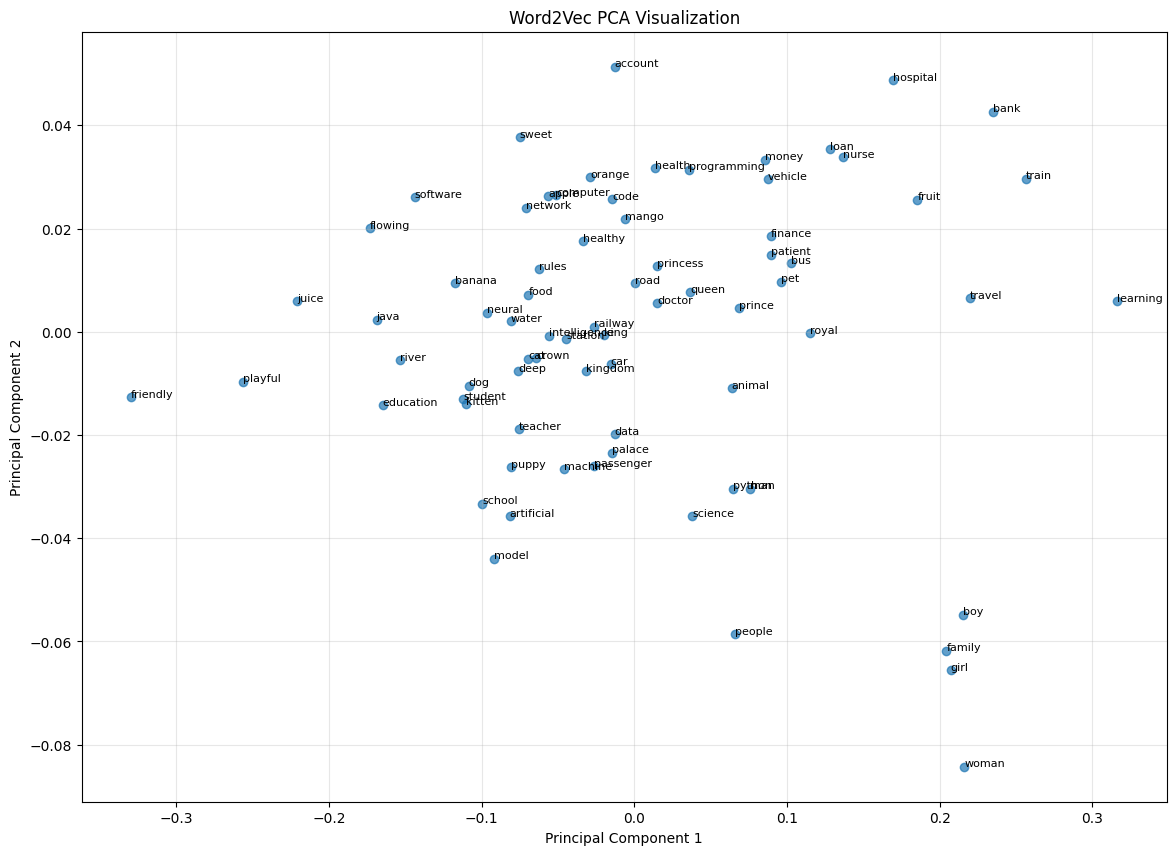

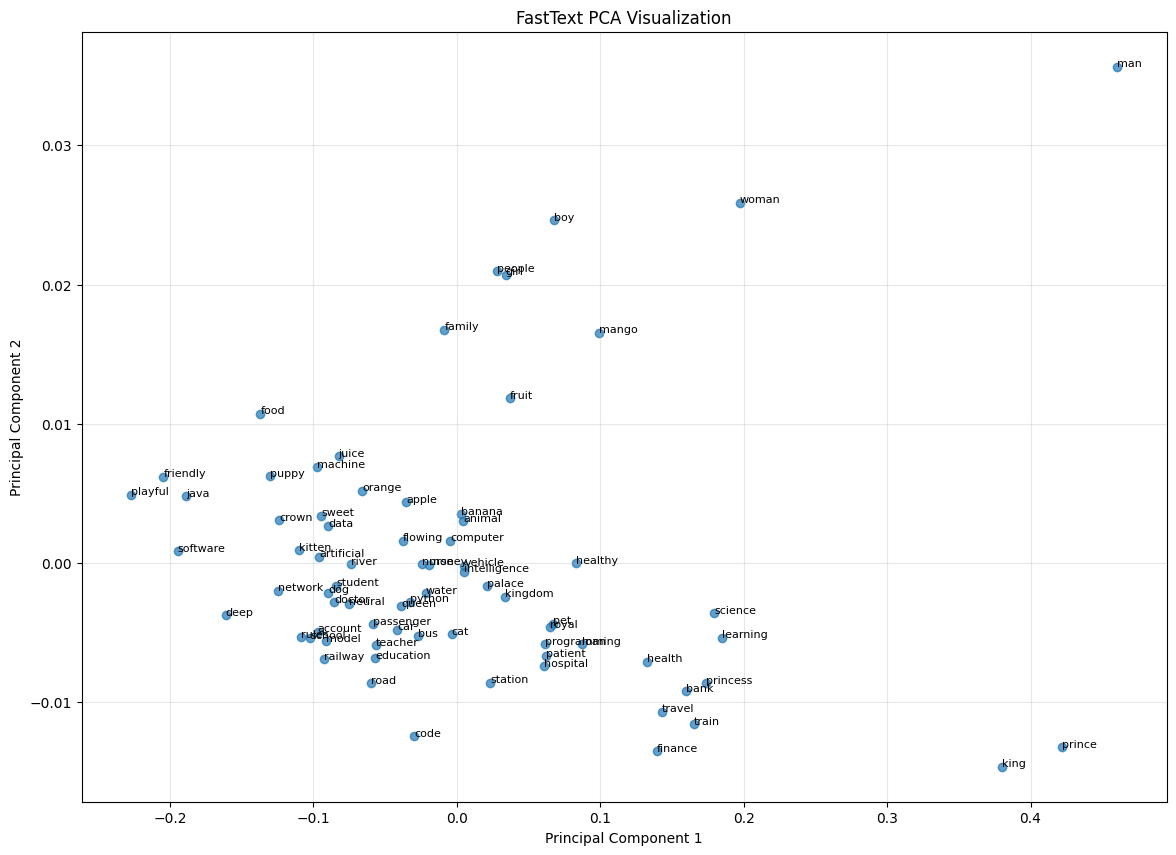


Number of vectors: 74
Number of labels: 74
Files ready for TensorFlow Embedding Projector!


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [7]:
!pip -q install --upgrade gensim smart_open

import numpy as np
import matplotlib.pyplot as plt
from gensim.models import Word2Vec, FastText
from sklearn.decomposition import PCA
from google.colab import files

sentences = [
    "king queen prince princess royal palace",
    "king rules kingdom royal crown",
    "queen rules kingdom palace crown",
    "man woman boy girl family people",
    "cat dog animal pet puppy kitten",
    "dog puppy animal pet friendly",
    "cat kitten animal pet playful",
    "apple orange mango fruit sweet",
    "banana apple fruit healthy food",
    "orange mango fruit juice sweet",
    "car bus train vehicle road travel",
    "train railway station travel passenger",
    "doctor nurse hospital patient health",
    "student teacher school learning education",
    "python java programming computer code",
    "computer code software programming python",
    "data science machine learning artificial intelligence",
    "machine learning neural network deep learning",
    "artificial intelligence data science model",
    "bank money loan finance account",
    "river bank water flowing"
]

tokens = [sentence.split() for sentence in sentences]

word2vec = Word2Vec(
    tokens, vector_size=50, window=3,
    min_count=1, sg=1, epochs=300,
    workers=1, seed=42
)

fasttext = FastText(
    tokens, vector_size=50, window=3,
    min_count=1, sg=1, epochs=300,
    workers=1, seed=42
)

words = word2vec.wv.index_to_key

print("Total unique words:", len(words))

# PCA Visualization
def plot_embeddings(model, title):
    vectors = np.array([model.wv[w] for w in words])
    reduced = PCA(n_components=2).fit_transform(vectors)

    plt.figure(figsize=(14, 10))
    plt.scatter(reduced[:, 0], reduced[:, 1], alpha=0.7)

    for i, word in enumerate(words):
        plt.annotate(
            word,
            (reduced[i, 0], reduced[i, 1]),
            fontsize=8
        )

    plt.title(title)
    plt.xlabel("Principal Component 1")
    plt.ylabel("Principal Component 2")
    plt.grid(alpha=0.3)
    plt.show()

plot_embeddings(word2vec, "Word2Vec PCA Visualization")
plot_embeddings(fasttext, "FastText PCA Visualization")

# Export for TensorFlow Embedding Projector
vectors = np.array([word2vec.wv[w] for w in words])

np.savetxt(
    "vectors.tsv",
    vectors,
    delimiter="\t",
    fmt="%.6f"
)

# No header row
with open("metadata.tsv", "w", encoding="utf-8") as f:
    for word in words:
        f.write(word + "\n")

print("\nNumber of vectors:", len(vectors))
print("Number of labels:", len(words))
print("Files ready for TensorFlow Embedding Projector!")

files.download("vectors.tsv")
files.download("metadata.tsv")

Task 5 — Comparative Analysis and Report

Aim: To compare traditional, static and contextual embeddings based on semantic representation, OOV handling, contextual understanding and computational requirements.

This cell generates the final comparison table and a simple Word2Vec versus FastText similarity comparison. It saves the table as a CSV file.

TF-IDF document similarity: 0.349

WORD SIMILARITY COMPARISON:


,Word Pair,Word2Vec,FastText
0,king - queen,0.985,0.998
1,cat - dog,0.970,0.990
2,apple - orange,0.979,0.996
3,car - train,0.980,0.997
4,python - java,0.969,0.993


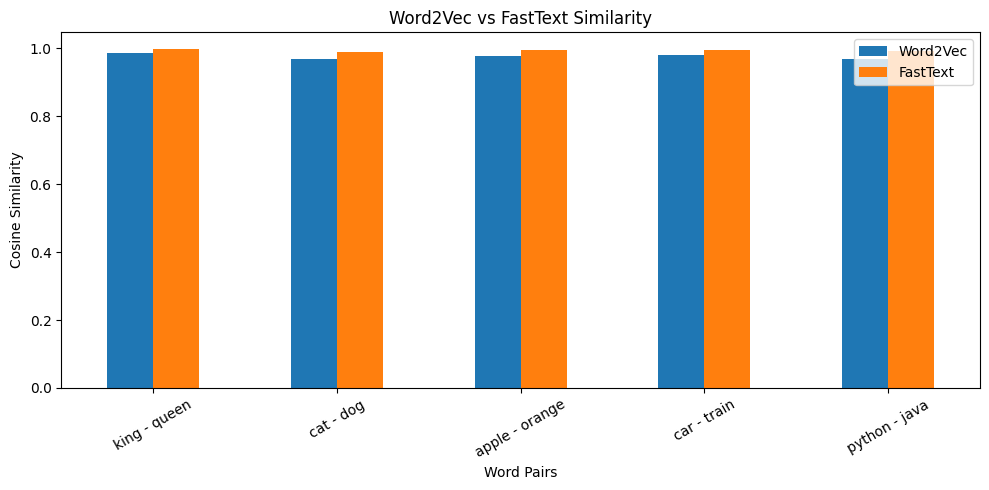


FINAL COMPARISON TABLE:


,Technique,Semantic Representation,OOV Handling,Contextual Understanding,Computational Requirement
0,TF-IDF,Word importance,No,No,Low
1,Word2Vec,Static semantic,No,No,Moderate
2,FastText,Subword semantic,Subword vectors,No,Moderate
3,Keras,Task-dependent,Requires OOV strategy,Depends on architecture,Variable
4,BERT,Contextual semantic,Subword tokenizer,Yes,High



CONCLUSION:
TF-IDF represents word importance in documents.
Word2Vec learns static word embeddings.
FastText uses subword information and supports OOV vectors.
Keras learns embeddings through neural training.
BERT produces context-dependent representations.


In [8]:
!pip -q install --upgrade gensim smart_open

import pandas as pd
import matplotlib.pyplot as plt
from gensim.models import Word2Vec, FastText
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity

sentences = [
    "king queen prince princess royal palace",
    "king rules kingdom royal crown",
    "queen rules kingdom palace crown",
    "man woman boy girl family people",
    "cat dog animal pet puppy kitten",
    "dog puppy animal pet friendly",
    "cat kitten animal pet playful",
    "apple orange mango fruit sweet",
    "banana apple fruit healthy food",
    "orange mango fruit juice sweet",
    "car bus train vehicle road travel",
    "train railway station travel passenger",
    "doctor nurse hospital patient health",
    "student teacher school learning education",
    "python java programming computer code",
    "computer code software programming python",
    "data science machine learning artificial intelligence",
    "machine learning neural network deep learning",
    "artificial intelligence data science model",
    "bank money loan finance account",
    "river bank water flowing"
]

tokens = [sentence.split() for sentence in sentences]

w2v = Word2Vec(
    tokens, vector_size=50, window=3,
    min_count=1, sg=1, epochs=300,
    workers=1, seed=42
)

ft = FastText(
    tokens, vector_size=50, window=3,
    min_count=1, sg=1, epochs=300,
    workers=1, seed=42
)

# TF-IDF document similarity
tfidf = TfidfVectorizer()
tfidf_vectors = tfidf.fit_transform(sentences)

doc_similarity = cosine_similarity(
    tfidf_vectors[0], tfidf_vectors[1]
)[0][0]

print("TF-IDF document similarity:",
      round(float(doc_similarity), 3))

# Word similarity comparison
pairs = [
    ("king", "queen"),
    ("cat", "dog"),
    ("apple", "orange"),
    ("car", "train"),
    ("python", "java")
]

results = []

for a, b in pairs:
    results.append({
        "Word Pair": f"{a} - {b}",
        "Word2Vec": float(w2v.wv.similarity(a, b)),
        "FastText": float(ft.wv.similarity(a, b))
    })

results_df = pd.DataFrame(results)

print("\nWORD SIMILARITY COMPARISON:")
display(results_df.round(3))

results_df.set_index("Word Pair").plot(
    kind="bar", figsize=(10, 5)
)

plt.title("Word2Vec vs FastText Similarity")
plt.xlabel("Word Pairs")
plt.ylabel("Cosine Similarity")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

# Final comparison
comparison = pd.DataFrame({
    "Technique": ["TF-IDF", "Word2Vec", "FastText", "Keras", "BERT"],
    "Semantic Representation": [
        "Word importance", "Static semantic",
        "Subword semantic", "Task-dependent",
        "Contextual semantic"
    ],
    "OOV Handling": [
        "No", "No", "Subword vectors",
        "Requires OOV strategy", "Subword tokenizer"
    ],
    "Contextual Understanding": [
        "No", "No", "No",
        "Depends on architecture", "Yes"
    ],
    "Computational Requirement": [
        "Low", "Moderate", "Moderate",
        "Variable", "High"
    ]
})

print("\nFINAL COMPARISON TABLE:")
display(comparison)

comparison.to_csv("comparison_table.csv", index=False)

print("\nCONCLUSION:")
print("TF-IDF represents word importance in documents.")
print("Word2Vec learns static word embeddings.")
print("FastText uses subword information and supports OOV vectors.")
print("Keras learns embeddings through neural training.")
print("BERT produces context-dependent representations.")